
# Water Segmentation with U-Net — Kolar Dam + Generalization Test

**Goal:** train a small U-Net to classify water vs. non-water pixels from Sentinel-2 imagery, then test whether it **generalizes to a water body it never saw during training** (Bhopal's Upper Lake) — a genuinely meaningful comparison against your fixed-threshold NDWI method.

**Pipeline:**
1. Authenticate with Earth Engine
2. Pull several small image patches from around Kolar Dam (training data) + one patch from Bhopal's Upper Lake (held-out test data)
3. Generate NDWI-based labels for each patch
4. Build a PyTorch Dataset from these patches
5. Define a small U-Net architecture
6. Train it
7. Evaluate on the held-out Upper Lake patch — compare U-Net's prediction vs. a plain NDWI threshold on that same new location
8. Visualize and interpret


In [1]:
!pip install geemap earthengine-api torch torchvision scikit-learn -q


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 32.4 MB/s eta 0:00:00


In [3]:
import ee
import geemap
import numpy as np
import matplotlib.pyplot as plt

ee.Authenticate()
ee.Initialize(project='geospatial-506611')



## 1. Define training patches (around Kolar Dam) + one held-out test patch (Upper Lake, Bhopal)

We take several small, slightly different sub-areas around Kolar Dam for training — this gives the model some variety (different parts of the reservoir's edge, different land backgrounds) without needing a huge dataset.

The Upper Lake patch is **never used in training** — it exists purely to test generalization.


In [5]:
# Training patch centers - small shifts around Kolar Dam to capture varied water/land boundaries
train_centers = [
    (22.9595, 77.3100),
    (22.9650, 77.3250),
    (22.9500, 77.3400),
    (22.9700, 77.3050),
    (22.9450, 77.3300),
]

# Held-out test location - Bhopal's Upper Lake (Bada Talab), NOT used in training
test_center = (23.2278, 77.3605)

PATCH_SIZE_DEG = 0.012   # roughly a ~1.3km x 1.3km patch at this latitude
SCALE = 10                # Sentinel-2 native resolution in meters

def make_patch_geometry(lat, lon, half_size=PATCH_SIZE_DEG/2):
    return ee.Geometry.Rectangle([lon - half_size, lat - half_size, lon + half_size, lat + half_size])

train_geoms = [make_patch_geometry(lat, lon) for lat, lon in train_centers]
test_geom = make_patch_geometry(*test_center)

print(f"{len(train_geoms)} training patches defined, 1 held-out test patch defined")


5 training patches defined, 1 held-out test patch defined


In [6]:
m = geemap.Map(center=[22.96, 77.32], zoom=11, basemap='SATELLITE')
for i, geom in enumerate(train_geoms):
    m.addLayer(geom, {}, f'train patch {i}')
m.addLayer(test_geom, {'color': 'red'}, 'test patch (Upper Lake)')
m

Map(center=[22.96, 77.32], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright'…


## 2. Pull each patch as a NumPy array (Green, NIR bands), compute NDWI label

For each patch: get a cloud-free May 2023 composite (same logic as your original project), extract bands B3 (Green) and B8 (NIR) as arrays, and compute the NDWI-based water mask — this becomes our training "label."


In [7]:
def mask_s2_clouds(image):
    qa = image.select('QA60')
    cloud_bit_mask = 1 << 10
    cirrus_bit_mask = 1 << 11
    mask = qa.bitwiseAnd(cloud_bit_mask).eq(0).And(qa.bitwiseAnd(cirrus_bit_mask).eq(0))
    return image.updateMask(mask).divide(10000)


def get_patch_arrays(geometry, year=2023, month=5, day_window=15, cloud_filter=20):
    center_date = ee.Date.fromYMD(year, month, 15)
    start = center_date.advance(-day_window, 'day')
    end = center_date.advance(day_window, 'day')

    collection = (ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
                  .filterBounds(geometry)
                  .filterDate(start, end)
                  .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', cloud_filter))
                  .map(mask_s2_clouds))

    image = collection.median().clip(geometry)

    # Pull Green (B3) and NIR (B8) as a stacked numpy array
    arr = geemap.ee_to_numpy(image, bands=['B3', 'B8'], region=geometry, scale=SCALE)
    return arr  # shape: (height, width, 2)


print("Pulling training patches...")
train_arrays = []
for i, geom in enumerate(train_geoms):
    arr = get_patch_arrays(geom)
    if arr is not None:
        train_arrays.append(arr)
        print(f"  Patch {i}: shape {arr.shape}")
    else:
        print(f"  Patch {i}: FAILED to retrieve (likely no clear imagery in window)")

print("\\nPulling held-out test patch (Upper Lake)...")
test_array = get_patch_arrays(test_geom)
print(f"  Test patch shape: {test_array.shape}")


Pulling training patches...
  Patch 0: shape (134, 134, 2)
  Patch 1: shape (135, 134, 2)
  Patch 2: shape (135, 134, 2)
  Patch 3: shape (134, 135, 2)
  Patch 4: shape (135, 135, 2)
\nPulling held-out test patch (Upper Lake)...
  Test patch shape: (135, 134, 2)



**If any patch failed above:** this usually means no cloud-free image was found in that specific 15-day window for that location — try widening `day_window` to 25-30 in the `get_patch_arrays` call for that patch, or just drop it if you have at least 3-4 successful training patches.

## 3. Compute NDWI labels for each patch


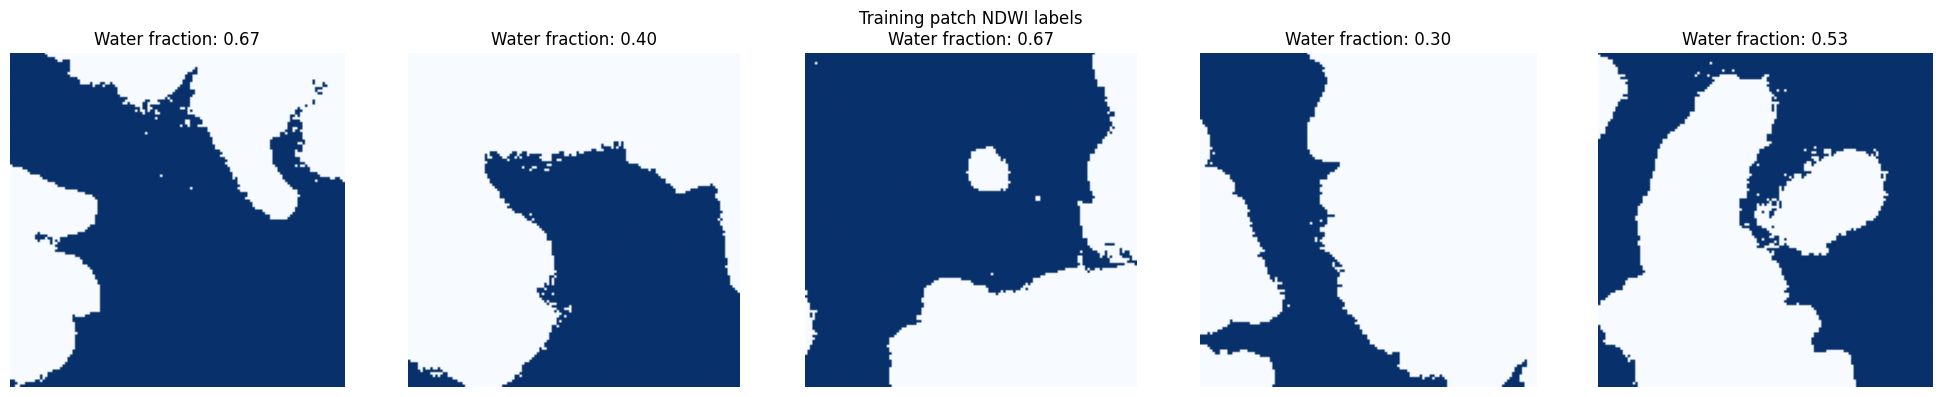

In [8]:
NDWI_THRESHOLD = 0.1

def compute_ndwi_label(arr):
    green = arr[:, :, 0]
    nir = arr[:, :, 1]
    ndwi = (green - nir) / (green + nir + 1e-8)  # small epsilon avoids divide-by-zero
    label = (ndwi > NDWI_THRESHOLD).astype(np.float32)
    return label

train_labels = [compute_ndwi_label(arr) for arr in train_arrays]
test_label = compute_ndwi_label(test_array)

# Quick visual sanity check - does the label look like a sensible water mask?
fig, axes = plt.subplots(1, len(train_labels), figsize=(4*len(train_labels), 4))
for ax, label in zip(axes, train_labels):
    ax.imshow(label, cmap='Blues')
    ax.set_title(f'Water fraction: {label.mean():.2f}')
    ax.axis('off')
plt.suptitle('Training patch NDWI labels')
plt.tight_layout()
plt.show()



**Check this visually:** do these look like sensible water-shape blobs, not random noise? If any patch is 0% or 100% water (no boundary at all), it's not useful training data — consider swapping its center coordinates slightly.

## 4. Build a PyTorch Dataset


In [9]:
import torch
from torch.utils.data import Dataset, DataLoader
import torch.nn as nn
import torch.nn.functional as F

TARGET_SIZE = 128  # resize all patches to a consistent size for batching

def preprocess(arr, label):
    # arr: (H, W, 2) -> normalize and resize to TARGET_SIZE x TARGET_SIZE
    img = arr.astype(np.float32)
    img = (img - img.min()) / (img.max() - img.min() + 1e-8)  # normalize to 0-1

    img_t = torch.from_numpy(img).permute(2, 0, 1).unsqueeze(0)  # (1, 2, H, W)
    label_t = torch.from_numpy(label).unsqueeze(0).unsqueeze(0)  # (1, 1, H, W)

    img_t = F.interpolate(img_t, size=(TARGET_SIZE, TARGET_SIZE), mode='bilinear', align_corners=False)
    label_t = F.interpolate(label_t, size=(TARGET_SIZE, TARGET_SIZE), mode='nearest')

    return img_t.squeeze(0), label_t.squeeze(0)


class WaterDataset(Dataset):
    def __init__(self, arrays, labels):
        self.data = [preprocess(a, l) for a, l in zip(arrays, labels)]

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        return self.data[idx]


train_dataset = WaterDataset(train_arrays, train_labels)
train_loader = DataLoader(train_dataset, batch_size=2, shuffle=True)

print(f"Training dataset size: {len(train_dataset)} patches")
sample_img, sample_label = train_dataset[0]
print(f"Image tensor shape: {sample_img.shape}, Label tensor shape: {sample_label.shape}")


Training dataset size: 5 patches
Image tensor shape: torch.Size([2, 128, 128]), Label tensor shape: torch.Size([1, 128, 128])



**What just happened:** each patch's (Green, NIR) array became a PyTorch tensor, resized to a consistent 128×128 so patches of slightly different original sizes can be batched together, and normalized to a 0-1 range (neural networks train better on normalized inputs than raw reflectance values).

## 5. Define a small U-Net



In [10]:
class DoubleConv(nn.Module):
    # Two conv layers in a row, each followed by ReLU activation - the basic building block used at every level of the U.
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.block(x)


class SmallUNet(nn.Module):
    def __init__(self, in_channels=2, out_channels=1):
        super().__init__()
        # Encoder (left side of the U - shrinking, learning abstract features)
        self.enc1 = DoubleConv(in_channels, 16)
        self.enc2 = DoubleConv(16, 32)
        self.pool = nn.MaxPool2d(2)

        # Bottleneck (bottom of the U)
        self.bottleneck = DoubleConv(32, 64)

        # Decoder (right side of the U - expanding back up, using skip connections)
        self.up2 = nn.ConvTranspose2d(64, 32, 2, stride=2)
        self.dec2 = DoubleConv(64, 32)  # 64 = 32 (upsampled) + 32 (skip connection from enc2)

        self.up1 = nn.ConvTranspose2d(32, 16, 2, stride=2)
        self.dec1 = DoubleConv(32, 16)  # 32 = 16 (upsampled) + 16 (skip connection from enc1)

        self.final = nn.Conv2d(16, out_channels, 1)  # 1x1 conv to get final per-pixel prediction

    def forward(self, x):
        # Encoder path, saving outputs for skip connections
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))

        # Bottleneck
        b = self.bottleneck(self.pool(e2))

        # Decoder path, concatenating skip connections from the matching encoder level
        d2 = self.up2(b)
        d2 = torch.cat([d2, e2], dim=1)  # the "skip connection" - borrowing fine detail from the encoder
        d2 = self.dec2(d2)

        d1 = self.up1(d2)
        d1 = torch.cat([d1, e1], dim=1)
        d1 = self.dec1(d1)

        return self.final(d1)


model = SmallUNet(in_channels=2, out_channels=1)
print(model)
print(f"\\nTotal parameters: {sum(p.numel() for p in model.parameters()):,}")


SmallUNet(
  (enc1): DoubleConv(
    (block): Sequential(
      (0): Conv2d(2, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU(inplace=True)
      (2): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (3): ReLU(inplace=True)
    )
  )
  (enc2): DoubleConv(
    (block): Sequential(
      (0): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU(inplace=True)
      (2): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (3): ReLU(inplace=True)
    )
  )
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (bottleneck): DoubleConv(
    (block): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU(inplace=True)
      (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (3): ReLU(inplace=True)
    )
  )
  (up2): ConvTranspose2d(64, 32, kernel_size=(2, 2), stride=(2, 2))
  (dec2): DoubleCo


**Reading this code against the "U" explanation from before:**
- `enc1`, `enc2` + `pool` = the left side of the U, shrinking the image while learning features
- `bottleneck` = the bottom of the U
- `up2`, `up1` = the right side of the U, expanding back up
- `torch.cat([..., skip connection])` = exactly the horizontal skip-connection lines in the U diagram — borrowing precise detail from the matching encoder level
- `final` = a 1×1 convolution that turns the last feature map into a single per-pixel water/not-water prediction

## 6. Train the model


Epoch 5/30 - loss: 0.6124
Epoch 10/30 - loss: 0.2633
Epoch 15/30 - loss: 0.0959
Epoch 20/30 - loss: 0.0689
Epoch 25/30 - loss: 0.0610
Epoch 30/30 - loss: 0.0621


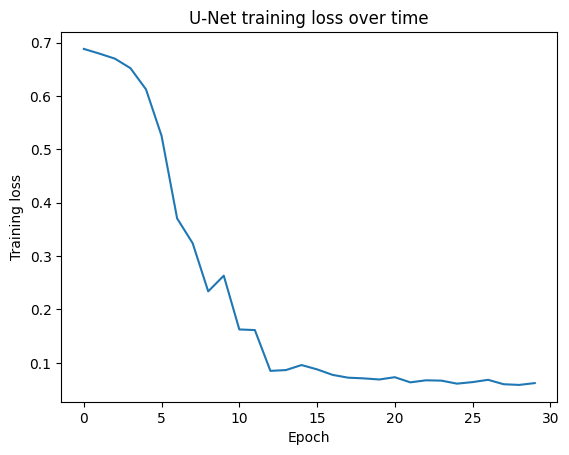

In [11]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = model.to(device)

optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
criterion = nn.BCEWithLogitsLoss()  # standard loss for binary (water/not-water) pixel classification

EPOCHS = 30
loss_history = []

for epoch in range(EPOCHS):
    model.train()
    epoch_loss = 0
    for imgs, labels in train_loader:
        imgs, labels = imgs.to(device), labels.to(device)

        optimizer.zero_grad()
        preds = model(imgs)
        loss = criterion(preds, labels)
        loss.backward()
        optimizer.step()

        epoch_loss += loss.item()

    avg_loss = epoch_loss / len(train_loader)
    loss_history.append(avg_loss)
    if (epoch + 1) % 5 == 0:
        print(f"Epoch {epoch+1}/{EPOCHS} - loss: {avg_loss:.4f}")

plt.plot(loss_history)
plt.xlabel('Epoch')
plt.ylabel('Training loss')
plt.title('U-Net training loss over time')
plt.show()



## 7. Evaluate on the held-out Upper Lake patch — the real test


In [12]:
from sklearn.metrics import jaccard_score, f1_score

model.eval()
test_img_t, test_label_t = preprocess(test_array, test_label)
test_img_t = test_img_t.unsqueeze(0).to(device)

with torch.no_grad():
    pred_logits = model(test_img_t)
    pred_probs = torch.sigmoid(pred_logits)
    pred_mask = (pred_probs > 0.5).float().cpu().squeeze().numpy()

true_mask = test_label_t.squeeze().numpy()

# IoU (Intersection over Union) and F1 - standard segmentation evaluation metrics
iou = jaccard_score(true_mask.flatten(), pred_mask.flatten(), zero_division=0)
f1 = f1_score(true_mask.flatten(), pred_mask.flatten(), zero_division=0)

print(f"U-Net on held-out Upper Lake patch:")
print(f"  IoU: {iou:.3f}")
print(f"  F1 score: {f1:.3f}")


U-Net on held-out Upper Lake patch:
  IoU: 0.718
  F1 score: 0.836



**What IoU and F1 mean:**
- **IoU (Intersection over Union):** of all the pixels either method called "water," what fraction did both agree on? 1.0 = perfect agreement, 0 = no overlap at all.
- **F1 score:** a balance between precision (of predicted water pixels, how many were actually water) and recall (of actual water pixels, how many did it correctly find). Also ranges 0-1, higher is better.

## 8. Visualize the comparison


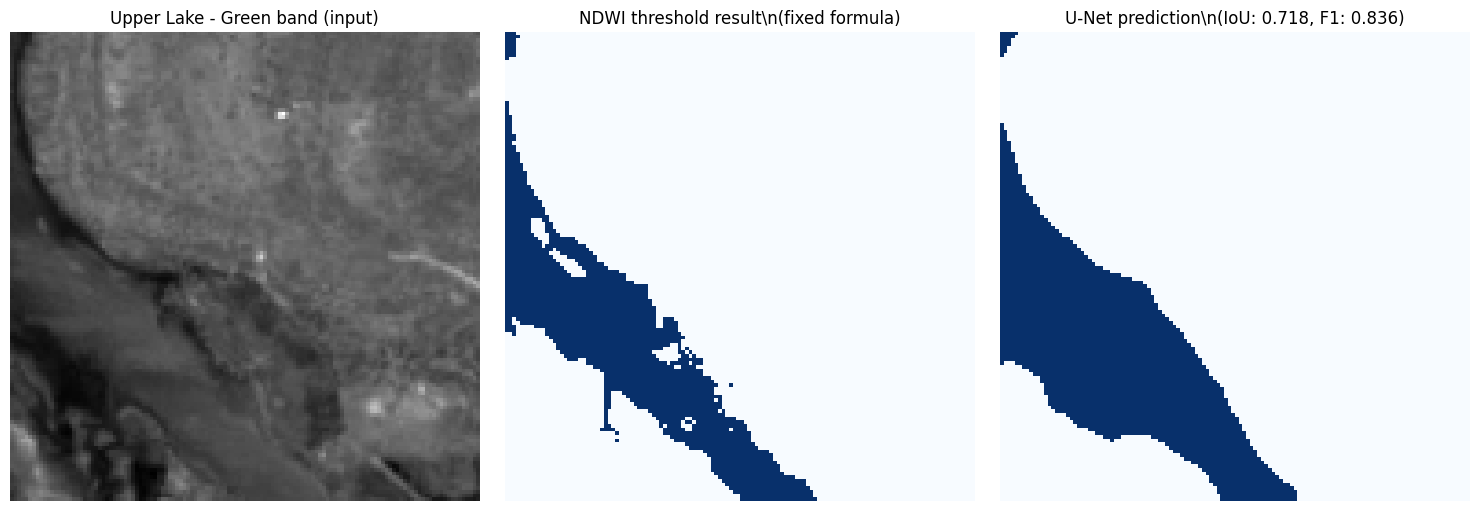

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(test_img_t.squeeze().cpu().numpy()[0], cmap='gray')
axes[0].set_title('Upper Lake - Green band (input)')
axes[0].axis('off')

axes[1].imshow(true_mask, cmap='Blues')
axes[1].set_title('NDWI threshold result\\n(fixed formula)')
axes[1].axis('off')

axes[2].imshow(pred_mask, cmap='Blues')
axes[2].set_title(f'U-Net prediction\\n(IoU: {iou:.3f}, F1: {f1:.3f})')
axes[2].axis('off')

plt.tight_layout()
plt.savefig('unet_vs_ndwi_comparison.png', dpi=200)
plt.show()
